# Step 6: PCA and LDA

**Question:** does compressing the 128 features with PCA or LDA make the models more (or less) robust to drift?

- **PCA** (unsupervised): keeps as many components as needed to explain 95% of the variance of the *training* data.
- **LDA** (supervised): keeps 4 components (the maximum for 5 gases), chosen to separate the gases in the *training* data.
- The pipeline is scaler -> PCA/LDA -> classifier, so both are **fitted on the training batches only** (tests prove the
  test batches cannot change them).
- Same five models, same default settings and same protocols as Step 5. The "None" column below is the Step 5 result.
- Nothing is tuned and nothing is chosen using the test batches.

In [1]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import data_loader as dl
from src import evaluation as ev
from src import models

pd.set_option("display.width", 160)
df = dl.remove_toluene(dl.load_all())
NAMES = models.BASELINE_NAMES
RED = ["None", "PCA", "LDA"]
RED_COLORS = {"None": "#8d99ae", "PCA": "#2a9d8f", "LDA": "#e76f51"}
Path("../results/models").mkdir(parents=True, exist_ok=True)

# Step 5 results are the "None" reference; re-check one number so we know they are reproducible
step5 = pd.read_csv("../results/step5_baseline_metrics.csv")
step5["reduction"] = "None"
check = ev.evaluate_split(models.get_baselines("None")["kNN"], df, ev.get_splits("A")[0])[0]
ref = step5[(step5["model"] == "kNN") & (step5["protocol"] == "A") & (step5["test_batch"] == "pooled")]["accuracy"].iloc[0]
assert np.isclose(check.query("test_batch == 'pooled'")["accuracy"].iloc[0], ref)
print("Step 5 reference reproduced (kNN protocol A pooled accuracy =", round(ref, 4), ")")

Step 5 reference reproduced (kNN protocol A pooled accuracy = 0.6963 )


## 1. How much does each reducer compress?

Training batches 1-3: PCA components for 90% / 95% / 99% variance: 8 11 21 (out of 128)


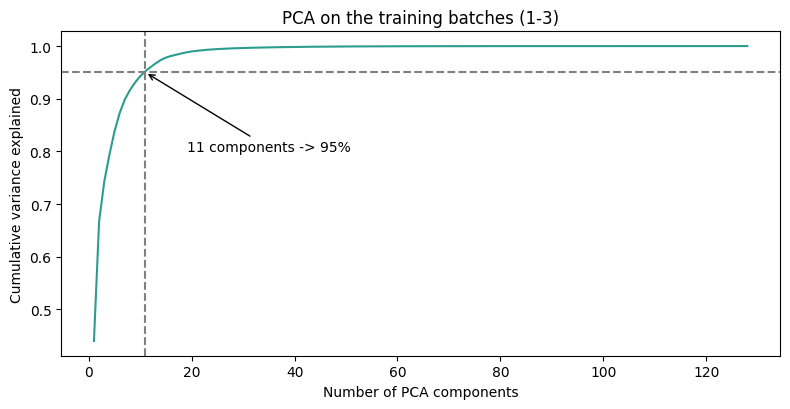

In [2]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
train = df[df["batch"].isin([1, 2, 3])]
z = StandardScaler().fit_transform(train[dl.FEATURE_COLS])
full = PCA(random_state=42).fit(z)
cum = np.cumsum(full.explained_variance_ratio_)
n95 = int(np.searchsorted(cum, 0.95) + 1)
n99 = int(np.searchsorted(cum, 0.99) + 1)
print(f"Training batches 1-3: PCA components for 90% / 95% / 99% variance:",
      int(np.searchsorted(cum, 0.90) + 1), n95, n99, "(out of 128)")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(range(1, 129), cum, color="#2a9d8f")
ax.axhline(0.95, color="grey", ls="--"); ax.axvline(n95, color="grey", ls="--")
ax.annotate(f"{n95} components -> 95%", (n95, 0.95), xytext=(n95 + 8, 0.80), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Number of PCA components"); ax.set_ylabel("Cumulative variance explained")
ax.set_title("PCA on the training batches (1-3)")
plt.tight_layout()
plt.savefig("../results/step6_pca_variance.png", dpi=150)
plt.show()

**What to notice:** the 128 features are highly compressible on the training batches: **11 components keep 95%** of
the variance (8 keep 90%, 21 keep 99%). So the data has a lot of overlapping information (as Step 2 hinted).

## 2. Run every model with PCA and with LDA on all protocols

In [3]:
runs = [step5]
n_components = {}
for red in ["PCA", "LDA"]:
    for name, make in models.get_baselines(red).items():
        parts = []
        m, _, fitted = ev.evaluate_split(make, df, ev.get_splits("A")[0], return_model=True)
        parts.append(m)
        joblib.dump(fitted, f"../results/models/{red.lower()}_{name.replace(' ', '_').lower()}_protocolA.joblib")
        if red == "PCA":
            n_components[name] = int(fitted.named_steps["reducer"].n_components_)
        for p in "BC":
            parts.append(ev.run_protocol(make, df, p)[0])
        m_all = pd.concat(parts, ignore_index=True)
        m_all.insert(0, "model", name)
        m_all["reduction"] = red
        runs.append(m_all)
    print(red, "done")

metrics = pd.concat(runs, ignore_index=True)
metrics.to_csv("../results/step6_reduction_metrics.csv", index=False)
print("PCA components actually used (same for all models, fitted on batches 1-3):", set(n_components.values()))

PCA done


LDA done
PCA components actually used (same for all models, fitted on batches 1-3): {11}


## 3. Protocol A (headline)

In [4]:
A = metrics[metrics["protocol"] == "A"]
pooled = A[A["test_batch"] == "pooled"]
acc = pooled.pivot(index="model", columns="reduction", values="accuracy").loc[NAMES, RED]
f1 = pooled.pivot(index="model", columns="reduction", values="macro_f1").loc[NAMES, RED]

summary = pd.concat({"pooled accuracy": acc, "pooled macro-F1": f1}, axis=1)
summary[("change in accuracy vs None", "PCA")] = acc["PCA"] - acc["None"]
summary[("change in accuracy vs None", "LDA")] = acc["LDA"] - acc["None"]
summary.round(3).to_csv("../results/step6_protocolA_summary.csv")
summary.round(3)

pooled accuracy               pooled macro-F1               change in accuracy vs None       
reduction                None    PCA    LDA            None    PCA    LDA                        PCA    LDA
model                                                                                                      
kNN                     0.696  0.683  0.669           0.707  0.693  0.677                     -0.013 -0.028
SVM                     0.727  0.670  0.661           0.740  0.695  0.672                     -0.057 -0.066
Decision Tree           0.497  0.530  0.617           0.466  0.515  0.609                      0.033  0.120
Random Forest           0.647  0.704  0.677           0.617  0.683  0.674                      0.057  0.029
Naive Bayes             0.565  0.521  0.716           0.567  0.509  0.716                     -0.044  0.151

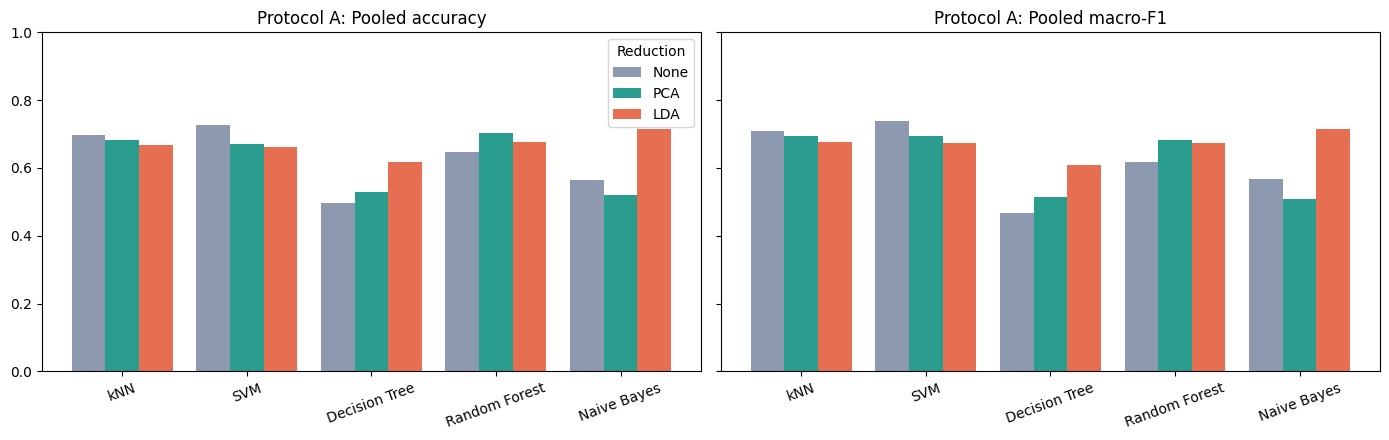

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
x = np.arange(len(NAMES))
for ax, tab, title in [(axes[0], acc, "Pooled accuracy"), (axes[1], f1, "Pooled macro-F1")]:
    for i, r in enumerate(RED):
        ax.bar(x + (i - 1) * 0.27, tab[r], 0.27, label=r, color=RED_COLORS[r])
    ax.set_xticks(x); ax.set_xticklabels(NAMES, rotation=20)
    ax.set_ylim(0, 1); ax.set_title(f"Protocol A: {title}")
axes[0].legend(title="Reduction")
plt.tight_layout()
plt.savefig("../results/step6_protocolA.png", dpi=150)
plt.show()

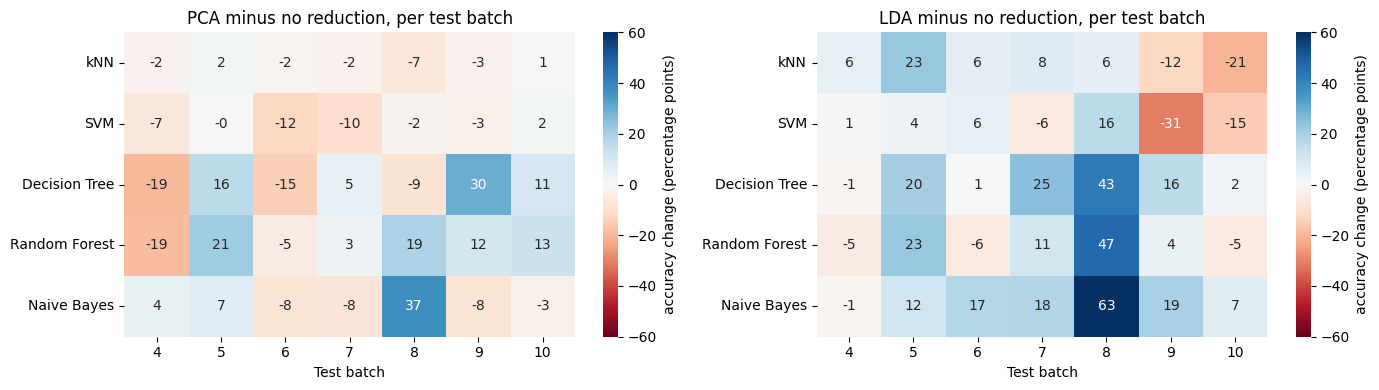

In [6]:
per_batch = A[A["test_batch"] != "pooled"].copy()
per_batch["test_batch"] = per_batch["test_batch"].astype(int)
accb = per_batch.pivot_table(index=["reduction", "model"], columns="test_batch", values="accuracy")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, red in zip(axes, ["PCA", "LDA"]):
    delta = (accb.loc[red] - accb.loc["None"]).loc[NAMES] * 100
    sns.heatmap(delta, annot=True, fmt=".0f", cmap="RdBu", center=0, vmin=-60, vmax=60, ax=ax,
                cbar_kws={"label": "accuracy change (percentage points)"})
    ax.set_title(f"{red} minus no reduction, per test batch")
    ax.set_xlabel("Test batch"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../results/step6_delta_per_batch.png", dpi=150)
plt.show()

**What to notice (protocol A, pooled accuracy, single run, untuned):**

| Model | None | PCA | LDA |
|---|---|---|---|
| kNN | 69.6% | 68.3% (-1.3) | 66.9% (-2.8) |
| SVM | **72.7%** | 67.0% (-5.7) | 66.1% (-6.6) |
| Decision Tree | 49.7% | 53.0% (+3.3) | 61.7% (+12.0) |
| Random Forest | 64.7% | 70.4% (+5.7) | 67.7% (+2.9) |
| Naive Bayes | 56.5% | 52.1% (-4.4) | 71.6% (+15.1) |

- **Reduction does not help every model.** It hurts the two strongest baselines (SVM, kNN) and helps the weaker ones
  (Decision Tree, Random Forest, and Naive Bayes with LDA).
- **The best result overall is unchanged:** SVM with no reduction (72.7%). Naive Bayes + LDA (71.6%) and
  Random Forest + PCA (70.4%) come close.
- **The effect varies a lot from batch to batch** (heatmap, in percentage points): from -31 (SVM + LDA, batch 9) to
  +63 (Naive Bayes + LDA, batch 8). LDA helps tree models and Naive Bayes a lot on batch 8 (+43 to +63) but hurts
  SVM and kNN on batches 9 and 10 (-12 to -31).
- **PCA is closer to neutral** than LDA: most changes are within about 20 points, with no consistent winner.

These are single runs without confidence intervals, so small gaps (a few points) are not conclusive.

## 4. Protocols B and C (supporting)

In [7]:
rows = {}
for p in "BC":
    d = metrics[(metrics["protocol"] == p)].copy()
    d["test_batch"] = d["test_batch"].astype(int)
    rows[f"{p} mean accuracy"] = d.groupby(["model", "reduction"])["accuracy"].mean().unstack()[RED].loc[NAMES]
bc = pd.concat(rows, axis=1)
bc.round(3).to_csv("../results/step6_protocolBC_summary.csv")
bc.round(3)

B mean accuracy               C mean accuracy              
reduction                None    PCA    LDA            None    PCA    LDA
model                                                                    
kNN                     0.407  0.468  0.331           0.826  0.820  0.828
SVM                     0.430  0.451  0.279           0.872  0.860  0.840
Decision Tree           0.551  0.510  0.433           0.743  0.748  0.796
Random Forest           0.506  0.535  0.378           0.848  0.817  0.820
Naive Bayes             0.528  0.351  0.378           0.558  0.666  0.830

**What to notice:**
- **Protocol B (train on batch 1 only):** LDA **lowers** the average accuracy for every model (for example SVM
  43.0% to 27.9%, kNN 40.7% to 33.1%). LDA learns its directions from the labels, and with only 371 training samples
  it has little to learn from. PCA is mixed: slightly up for kNN, SVM and Random Forest, down for Decision Tree and
  clearly down for Naive Bayes (52.8% to 35.1%).
- **Protocol C (retrain on all earlier batches):** the best models barely change (SVM 87.2% to 86.0% with PCA and
  84.0% with LDA; Random Forest 84.8% to 81.7% and 82.0%; kNN about the same). Naive Bayes gains a lot (55.8% to 66.6%
  with PCA and 83.0% with LDA) and Decision Tree gains with LDA (74.3% to 79.6%).

So when there is plenty of recent labelled data, reduction is mostly unnecessary for the strong models, and it
mainly rescues the weak ones.

## 5. What the reducers do to the data (LDA picture)

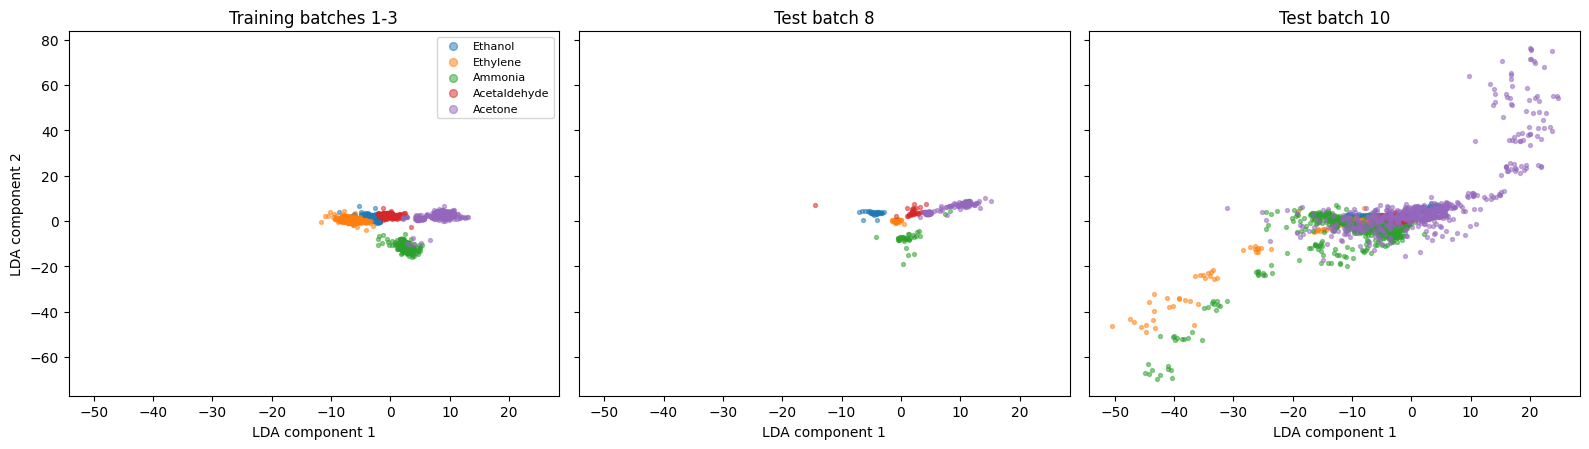

In [8]:
make = models.get_baselines("LDA")["kNN"]
_, _, fitted = ev.evaluate_split(make, df, ev.get_splits("A")[0], return_model=True)
def lda_coords(frame):
    return fitted.named_steps["reducer"].transform(fitted.named_steps["scaler"].transform(frame[dl.FEATURE_COLS].to_numpy()))

GASES = ["Ethanol", "Ethylene", "Ammonia", "Acetaldehyde", "Acetone"]
colors = dict(zip(GASES, sns.color_palette("tab10")[:5]))
panels = [("Training batches 1-3", df[df["batch"].isin([1, 2, 3])]),
          ("Test batch 8", df[df["batch"] == 8]),
          ("Test batch 10", df[df["batch"] == 10])]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
for ax, (title, frame) in zip(axes, panels):
    c = lda_coords(frame)
    for g in GASES:
        mk = (frame["gas"] == g).to_numpy()
        ax.scatter(c[mk, 0], c[mk, 1], s=8, alpha=0.5, color=colors[g], label=g)
    ax.set_title(title); ax.set_xlabel("LDA component 1")
axes[0].set_ylabel("LDA component 2"); axes[0].legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.savefig("../results/step6_lda_space.png", dpi=150)
plt.show()

**What to notice (first two of the four LDA components, fitted on batches 1-3):**
- **Training batches:** the five gases form compact groups that are clearly separated, which is what LDA is designed to do.
- **Batch 8:** the groups are shifted and stretched but still mostly distinguishable.
- **Batch 10:** points spread far outside the range seen in training (component 1 down to about -50, component 2 from
  about -70 to +75) and several gases overlap heavily. A boundary learned on the training region cannot handle this.

LDA picks directions that separate the gases *as they looked in batches 1-3*. When drift moves the data, those same
directions can stop working. This is a plausible reason LDA hurts SVM and kNN on batches 9 and 10, but we did not test
that explanation directly.

## Summary of Step 6
- PCA needs only 11 components for 95% of the training variance (out of 128).
- **No reducer improves the best baseline.** SVM without reduction (72.7%) is still the best on protocol A.
- Reduction **helps weaker models** (Decision Tree, Random Forest, Naive Bayes + LDA) and **hurts the stronger ones**
  (SVM, kNN), so PCA/LDA is not a general drift fix here.
- LDA is risky with little training data (protocol B) and when data moves outside the training region (batch 10).
- Effects vary hugely by batch (-31 to +63 points), and results are single runs without confidence intervals (Step 10).
- Both reducers are fitted on training batches only, which tests confirm.